In [35]:
import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore') 


In [36]:
import os 
cell_df = pd.read_csv("cell_samples.csv")
cell_df

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2,1,1,1,2
695,841769,2,1,1,1,2,1,1,1,1,2
696,888820,5,10,10,3,7,3,8,10,2,4
697,897471,4,8,6,4,3,4,10,6,1,4


In [37]:
cell_df["Class"] = cell_df["Class"].replace([2],0) #Tumor Benigno
cell_df["Class"] = cell_df["Class"].replace([4],1)
cell_df

,ID,Clump,UnifSize,UnifShape,MargAdh,SingEpiSize,BareNuc,BlandChrom,NormNucl,Mit,Class
0,1000025,5,1,1,1,2,1,3,1,1,0
1,1002945,5,4,4,5,7,10,3,2,1,0
2,1015425,3,1,1,1,2,2,3,1,1,0
3,1016277,6,8,8,1,3,4,3,7,1,0
4,1017023,4,1,1,3,2,1,3,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2,1,1,1,0
695,841769,2,1,1,1,2,1,1,1,1,0
696,888820,5,10,10,3,7,3,8,10,2,1
697,897471,4,8,6,4,3,4,10,6,1,1


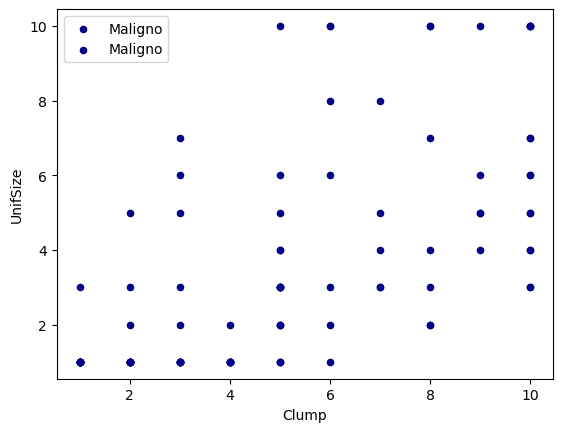

In [38]:
ax = cell_df[cell_df["Class"] == 1][0:50].plot(kind="scatter",x="Clump", y= "UnifSize", color="DarkBlue", label="Maligno")
ax = cell_df[cell_df["Class"] == 0][0:50].plot(kind="scatter",x="Clump", y= "UnifSize", color="DarkBlue", label="Maligno",ax=ax)
plt.show()

In [39]:
#Pre-Procesamiento de datos y selección
cell_df.dtypes

ID              int64
Clump           int64
UnifSize        int64
UnifShape       int64
MargAdh         int64
SingEpiSize     int64
BareNuc        object
BlandChrom      int64
NormNucl        int64
Mit             int64
Class           int64
dtype: object

In [40]:
#Eliminación de renglones no numéricas en BareNuc
cell_df = cell_df[pd.to_numeric(cell_df["BareNuc"], errors = "coerce").notnull()]
cell_df["BareNuc"]=cell_df["BareNuc"].astype("int")
cell_df.dtypes

ID             int64
Clump          int64
UnifSize       int64
UnifShape      int64
MargAdh        int64
SingEpiSize    int64
BareNuc        int64
BlandChrom     int64
NormNucl       int64
Mit            int64
Class          int64
dtype: object

In [41]:
feature_df = cell_df[["Clump","UnifSize","UnifShape","MargAdh", "SingEpiSize","BareNuc","BlandChrom","NormNucl","Mit"]]
x=np.asarray(feature_df)
x[0:5]

array([[ 5,  1,  1,  1,  2,  1,  3,  1,  1],
       [ 5,  4,  4,  5,  7, 10,  3,  2,  1],
       [ 3,  1,  1,  1,  2,  2,  3,  1,  1],
       [ 6,  8,  8,  1,  3,  4,  3,  7,  1],
       [ 4,  1,  1,  3,  2,  1,  3,  1,  1]])

In [42]:
cell_df["Class"] = cell_df["Class"].astype("int")
y = np.asarray(cell_df["Class"])
y[0:5]


array([0, 0, 0, 0, 0])

In [43]:
# Creación de grupos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=4)

print("Grupo de entrenamiento", X_train.shape, y_train.shape)
print("Grupo de prueba", X_test.shape, y_test.shape)

Grupo de entrenamiento (546, 9) (546,)
Grupo de prueba (137, 9) (137,)


# Modelación con SVM

Opciones de Kernel (Transformaciones):

1. Linear
2. Polynomial
3. Radial Basis
4. Sigmoid


In [44]:
from sklearn import svm
clf = svm.SVC(kernel="rbf")
clf.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [45]:
#Predicción para la base de prueba
yhat= clf.predict(X_test)
yhat[0:5]

array([0, 1, 0, 1, 0])

In [46]:
#Creación matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred =clf.predict(x)
cm = confusion_matrix(y_test, yhat)
cm

array([[85,  5],
       [ 0, 47]])

In [47]:
y_test

array([0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 1])

In [48]:
yhat

array([0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 1])

In [49]:
z=y_test-yhat
z

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1, -1,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0])

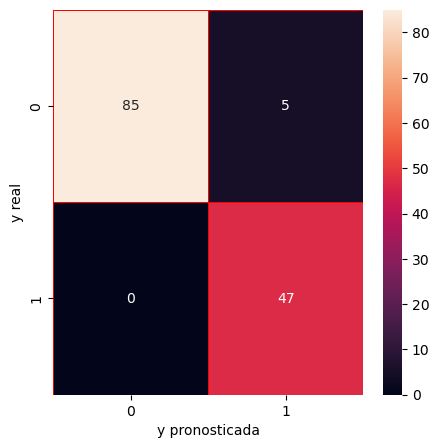

In [50]:
#Visualización de la matriz de confusión
import seaborn as sns
f, ax =plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5,linecolor="red",fmt=".0f", ax=ax)
plt.xlabel ("y pronosticada")
plt.ylabel("y real")
plt.show()


# Estadísticas de desempeño

In [51]:
from sklearn.metrics import classification_report
cfn_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_resport(y_test, yhat))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97        90
           1       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137



# Determinación de niveles de Precisión
Precision = Porcentaje de predicciones correctas relativas al total de predicciones
* El total se calcula por columna
* Se contesta la pregunta ¿Qué porcentaje de las veces que hacemos un pronóstico de cierto tipo éste es correcto?
  

In [52]:
PrecisionBenigno = cm[0,0]/(cm[0,0]+cm[1,0])
PrecisionBenigno

1.0

In [54]:
PrecisionMaligno = cm[1,1] /(cm[1,1]+cm[0,1])
PrecisionMaligno


0.9038461538461539

# DTERMINACIÓN DE NIVELES DE RECUPERACIÓN (RECALL)
La recuperación (Recall)= Porcentaje de predicciones correctas relativas al total de valores reales
* El total se calcula por renglón
* Se contesta la pregunta: ¿Qué porcentaje de las veces que se tiene un valor es identificado?

In [88]:
RecallBenigno = cm[0,0] / (cm[0,0] + cm[0,1])
RecallBenigno

0.6

In [89]:
RecallMaligno = cm[1,1]/(cm[1,0] +cm[1,1])
RecallMaligno

0.0

# Determinación del Score F1
F1 Score= Media armónica ponderada de la precision y la recuperación. Cuánto más se acerque a 1, mejor será el modeo
* F1 Score =2*(Precision+Recall)/(Precision + Recall)

In [90]:
F1Benigno = 2*(PrecisionBenigno*RecallBenigno)/(PrecisionBenigno +RecallBenigno)
F1Benigno

0.7499999999999999

In [91]:
F1Maligno = 2*(PrecisionMaligno*RecallMaligno)/(PrecisionMaligno+RecallMaligno)
F1Maligno

0.0

# Determinación de soportes
Soporte = Número de observaciones que pertenecen en forma real a cada clase posible (Total por renglón)


In [92]:
SoporteBenigno = cm[0,0] + cm[0,1]
SoporteBenigno

90

In [93]:
SoporteMaligno = cm[1,0]+cm[1,1]
SoporteMaligno

47

# Determinación de la Precision Global.
Accuracy = Porcentaje de predicciones correctas


In [94]:
Correctos = cm[0,0]+cm[1,1]
Incorrectos = cm[0,1] +cm[1,0]
PrecisionGlobal = Correctos/(Correctos+Incorrectos)
PrecisionGlobal

0.39416058394160586

# Promedios simples por indicador (Macro Average)
Promedio simple por Precision, Recuperación y F1 Score


In [95]:
MacroAvgPrecision = (PrecisionBenigno +PrecisionMaligno)/2
MacroAvgPrecision

0.9519230769230769

In [96]:
MacroAvgRecall = (RecallBenigno + RecallMaligno)/2
MacroAvgRecall

0.3

In [97]:
MacroF1Score= (F1Benigno +F1Maligno)/2
MacroF1Score

0.37499999999999994

# Promedios ponderados por indicadro (Weighted Average)
Promedios ponderados de a cuerdo a soportes por indicador

In [98]:
PesoBenigno = SoporteBenigno / (SoporteBenigno + SoporteMaligno)
PesoMaligno = SoporteMaligno/ (SoporteBenigno + SoporteMaligno) 

In [99]:
WAvgPrecision = PrecisionBenigno + PesoBenigno + PrecisionMaligno + PesoMaligno
WAvgPrecision

2.9038461538461537

In [100]:
WAvgRecall = RecallBenigno + PesoBenigno + RecallMaligno + PesoMaligno
WAvgRecall

1.6

In [101]:
WAvgF1Score = F1Benigno + PesoBenigno + F1Maligno +PesoMaligno
WAvgF1Score

1.75

# Prueba de SVM con Kernel Lineal

In [102]:
clf = svm.SVC(kernel="linear")
clf.fit(X_train, y_train)

yhat= clf.predict(X_test)
yhat[0:5]

from sklearn.metrics import confusion_matrix
y_pred =clf.predict(x)
cm = confusion_matrix(y_test, yhat)
cm

array([[85,  5],
       [ 0, 47]])

In [103]:
from sklearn.metrics import classification_report
cfn_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97        90
           1       0.90      1.00      0.95        47

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.97      0.96      0.96       137



# Prueba de SVM con Kernel Polinomial

In [104]:
clf = svm.SVC(kernel="poly")
clf.fit(X_train, y_train)

yhat= clf.predict(X_test)
yhat[0:5]

from sklearn.metrics import confusion_matrix
y_pred =clf.predict(x)
cm = confusion_matrix(y_test, yhat)
cm

array([[86,  4],
       [ 0, 47]])

In [105]:
from sklearn.metrics import classification_report
cfn_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98        90
           1       0.92      1.00      0.96        47

    accuracy                           0.97       137
   macro avg       0.96      0.98      0.97       137
weighted avg       0.97      0.97      0.97       137



# Prueba SVM con Kernel Sigmoide

In [106]:
clf = svm.SVC(kernel="sigmoid")
clf.fit(X_train, y_train)

yhat= clf.predict(X_test)
yhat[0:5]

from sklearn.metrics import confusion_matrix
y_pred =clf.predict(x)
cm = confusion_matrix(y_test, yhat)
cm

array([[54, 36],
       [47,  0]])

In [107]:
from sklearn.metrics import classification_report
cfn_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.53      0.60      0.57        90
           1       0.00      0.00      0.00        47

    accuracy                           0.39       137
   macro avg       0.27      0.30      0.28       137
weighted avg       0.35      0.39      0.37       137

